# Workshop 04 — Python, NumPy & Linear Regression from Scratch

**Machine Learning for Media Production · 2-hour coding workshop**

**The question:** Can a simple model learn a character's horizontal motion from animation frames?

By the end of the workshop, you will have written the key parts of a linear regression model **yourself**, without using `scikit-learn` to fit it.

**How to work:** Run cells in order, complete each `TODO`, then run its checks. Replace any `raise NotImplementedError(...)` placeholder with your own working code. Use the short examples and mathematical explanations as references, but **do not ask an AI assistant to write the entire solution**. Asking what an error means or how Python syntax works is fine.

| Section | Focus |
|:--|:--|
| 00 · Setup | Environment and motion data |
| 01 · Python | Lists, loops, conditions, functions |
| 02 · NumPy | Arrays, shapes, vectorisation, `@` |
| 03 · Prediction & Loss | `y = wx + b`, residuals, MSE |
| 04 · Gradient Descent | Derivatives, gradients, training loop |
| 05 · Multiple Inputs | Feature matrices and weights |
| 06 · Assignment | A single extension of this notebook |

**Requirements:** Python 3.10+, NumPy, Matplotlib, and a working Jupyter kernel. No extra dataset or downloads are required.

## Setup

download this ipynb file and put it in your `MLMPworkshop/workshop04_Python_NumPy_LinearRegression/`. should be in `~/Desktop/MLMPworkshop`.

```bash
cd ~/Desktop/MLMPworkshop/workshop04_Python_NumPy_LinearRegression/
ls 
# Workshop04_Python_NumPy_LinearRegression.ipynb
uv init
uv venv --python 3.11
source .venv/bin/activate  # Linux / macOS
uv add numpy matplotlib ipykernel notebook
```
go to your `.gitignore` file and add `.ipynb_checkpoints` in the last line.
`
## 00 · our motion data
We have eleven measurements of a character moving horizontally. `frames` contains frame numbers; `positions` contains the observed horizontal positions in arbitrary scene units.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

print("NumPy:", np.__version__)

frames = [0, 3, 6, 9, 12, 15, 18, 21, 24, 27, 30]
positions = [1.52, 1.97, 2.55, 3.02, 3.49, 4.01, 4.47, 5.04, 5.51, 5.94, 6.50]

assert len(frames) == len(positions)
print("Samples:", len(frames))
print("First sample: frame", frames[0], "→ position", positions[0])

NumPy: 2.2.6
Samples: 11
First sample: frame 0 → position 1.52


**Our running example**

- **Input (`x`)**: frame / time.
- **Target (`y`)**: horizontal character position.
- **Prediction (`ŷ`)**: where our model thinks the character should be.

The goal is to learn the mapping **input → predicted position**, not to memorise the list.

## 01 · Python fundamentals — 20 min

### 1.1 Read a list and run a loop

- A **list** stores multiple values.
- An **index** retrieves a value, starting at `0`.
- A `for` loop repeats a block of code.
- A function receives inputs and uses `return` to give a result back to the caller. `print()` only displays something.

In [2]:
print("First frame:", frames[0])
print("Last frame:", frames[-1])
print("Number of frames:", len(frames))

for frame in frames[:3]:
    print("Frame:", frame)

First frame: 0
Last frame: 30
Number of frames: 11
Frame: 0
Frame: 3
Frame: 6


### Task 1 — Mean with a Python loop

Write `manual_mean(values)` **without** `sum()`, `np.mean()`, or NumPy.

Steps to think about: start a running total; visit each value; divide by the number of values. If the list is empty, return `None`.

In [7]:
def manual_mean(values):
    if len(values) == 0:
        return None

    total = 0.0
    for value in values:
        # TODO 1: Add value to the running total.
        total+=value

    mean = total/len(values)
    # TODO 2: Return the mean (not just print it).
    return mean

In [8]:
# Check Task 1. Run only after you fill in manual_mean().
assert manual_mean([]) is None
assert manual_mean([2, 4, 6]) == 4
assert manual_mean([-2, 0, 2]) == 0
print("Task 1 passed")

Task 1 passed


### Task 2 — `if` + loop + function

Write `count_above_mean(values)`. Count how many values are **strictly greater** than the mean. An empty list should give `0`.

**Example:** `[3, 7, 2, 9, 4]` has mean `5`; the answer is `2`.

Reuse your `manual_mean()` function; do not calculate the mean again from scratch.

In [9]:
def count_above_mean(values):
    if len(values) == 0:
        return 0

    average = manual_mean(values)
    count = 0

    for value in values:
        if value > average:
            count +=1

    # TODO: Return the count.
    return count

In [10]:
assert count_above_mean([3, 7, 2, 9, 4]) == 2
assert count_above_mean([2, 2, 2]) == 0
assert count_above_mean([-2, -1, -3]) == 1
assert count_above_mean([]) == 0
print("Task 2 passed")

Task 2 passed


**Pause and explain (30 seconds):** Why does `for value in values` make more sense here than `for i in range(len(values))`? When would an index be useful?

In [12]:
values = [3, 7, 2, 9, 4]
for value in values:
    print(value)

3
7
2
9
4


In [13]:
for i in range(len(values)):
    print(i)

0
1
2
3
4


In [16]:
for i in range(len(values)):
    print(values[i])

3
7
2
9
4


## 02 · NumPy and linear algebra

### 2.1 Lists → arrays, and why shape matters

NumPy helps us work with many numbers at once. We will use **time normalised to `[0, 1]`** rather than raw frame numbers; the smaller input scale makes our later learning-rate exercise easier to control.

In [20]:
frames

[0, 3, 6, 9, 12, 15, 18, 21, 24, 27, 30]

In [22]:
frame_array = np.array(frames, dtype=float)
frame_array

array([ 0.,  3.,  6.,  9., 12., 15., 18., 21., 24., 27., 30.])

In [24]:
positions

[1.52, 1.97, 2.55, 3.02, 3.49, 4.01, 4.47, 5.04, 5.51, 5.94, 6.5]

In [26]:
y = np.array(positions, dtype=float)
y

array([1.52, 1.97, 2.55, 3.02, 3.49, 4.01, 4.47, 5.04, 5.51, 5.94, 6.5 ])

In [27]:
x = frame_array / 30.0
x

array([0. , 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1. ])

In [28]:
print("x:", x)
print("x.shape:", x.shape)
print("y.shape:", y.shape)
print("First 3 targets:", y[:3])

print("Mean from your function:", manual_mean(positions))
print("Mean from NumPy:", np.mean(y))

x: [0.  0.1 0.2 0.3 0.4 0.5 0.6 0.7 0.8 0.9 1. ]
x.shape: (11,)
y.shape: (11,)
First 3 targets: [1.52 1.97 2.55]
Mean from your function: 4.001818181818181
Mean from NumPy: 4.001818181818181


### 2.2 Slicing, reshape, and dimensions

For a one-dimensional array, `shape` looks like `(N,)`. Converting it to a **column** makes the shape `(N, 1)`.

- **Samples**: number of observations / rows.
- **Features**: number of input measurements per observation / columns.

**Task 3:** Create `x_column` from `x` using `reshape`. Do not change the values or their order.

In [31]:
# TODO: Convert x of shape (11,) into x_column of shape (11, 1).
x_column = x.reshape(11,1)
assert isinstance(x_column, np.ndarray), "x_column must be a NumPy array"
assert x_column.shape == (11, 1)
assert np.allclose(x_column[:, 0], x)
print("Task 3 passed:", x_column.shape)

Task 3 passed: (11, 1)


In [32]:
x_column

array([[0. ],
       [0.1],
       [0.2],
       [0.3],
       [0.4],
       [0.5],
       [0.6],
       [0.7],
       [0.8],
       [0.9],
       [1. ]])

### 2.3 Element-wise multiplication vs matrix multiplication

These operations are **different**:

- `A * w`: element-wise multiplication (NumPy may **broadcast** `w`).
- `A @ w`: matrix multiplication. For a matrix with shape `(N, F)` and a weight vector with shape `(F,)`, the result has shape `(N,)`.

**Important:** The inner dimensions must match for `@`. For `*`, NumPy compares shapes from the **rightmost** dimension and allows matching sizes or size `1`.

In [33]:
A = np.array([[1.0, 2.0],
              [3.0, 4.0],
              [5.0, 6.0]])
w_demo = np.array([0.2, 0.8])

print("A.shape:", A.shape)
print("w_demo.shape:", w_demo.shape)
print("A * w_demo:", A * w_demo)
print("A @ w_demo:", A @ w_demo)

A.shape: (3, 2)
w_demo.shape: (2,)
A * w_demo: [[0.2 1.6]
 [0.6 3.2]
 [1.  4.8]]
A @ w_demo: [1.8 3.8 5.8]


**Task 4 — Matrix prediction.** Finish the function to produce **one value per row** of `A` using matrix multiplication, not a Python loop.

In [34]:
def matrix_predict(A, w):
    i = A @ w
    # TODO: Use the matrix multiplication operator (@).
    return i

assert np.allclose(matrix_predict(np.eye(2), np.array([3.0, 7.0])), [3.0, 7.0])
assert matrix_predict(A, w_demo).shape == (3,)
assert np.allclose(matrix_predict(A, w_demo), [1.8, 3.8, 5.8])
print("Task 4 passed")

Task 4 passed


## 03 · Linear regression: prediction and loss — 25 min

### 3.1 From a line to a prediction

A one-variable linear regression model is a line:

$$
\hat{y} = wx + b
$$

- `w` (**weight / slope**): how much the predicted position changes when `x` increases by `1`.
- `b` (**bias / intercept**): the predicted position when `x = 0`.

The model does not know `w` or `b` yet. First, **you** will try some values; later, gradient descent will update them automatically.

**Task 5:** Implement `predict(x, w, b)`. It must work for both a single number and a NumPy array, and must return predictions rather than printing them.

In [35]:
def predict(x, w, b):
    y = w*x + b
    # TODO: Implement the linear equation shown above.
    return y

assert np.isclose(predict(2.0, 3.0, 1.0), 7.0)
assert np.allclose(predict(np.array([0.0, 1.0]), 2.0, 1.0), [1.0, 3.0])
print("Task 5 passed")

Task 5 passed


### 3.2 Residual and Mean Squared Error (MSE)

A **residual** is the prediction minus the target: `error = prediction - target`.

$$
\mathrm{MSE} = \frac{1}{N}\sum_{i=1}^{N}(\hat{y}_i-y_i)^2
$$

Squaring means positive and negative errors do not cancel. A **smaller MSE** means closer predictions **on this dataset**.

**Task 6:** Implement `compute_mse(y_true, y_pred)` with NumPy. Do not use `sklearn`.

In [38]:
def compute_mse(y_true, y_pred):
    n=0
    for i in range(len(y_pred)):
        m = (y_pred[i] - y_true[i])**2
        n+=m
    mse = n/len(y_pred)
    return mse

assert np.isclose(compute_mse(np.array([1., 2.]), np.array([1., 2.])), 0.0)
assert np.isclose(compute_mse(np.array([1., 2.]), np.array([2., 3.])), 1.0)
print("Task 6 passed")

Task 6 passed


In [41]:
def compute_mse(y_true, y_pred):
    return np.mean((y_pred - y_true) ** 2)
    
assert np.isclose(compute_mse(np.array([1., 2.]), np.array([1., 2.])), 0.0)
assert np.isclose(compute_mse(np.array([1., 2.]), np.array([2., 3.])), 1.0)
print("Task 6 passed")

Task 6 passed


### 3.3 See your first prediction

The next cell is **visualisation code you can run directly**. You do *not* need to memorise Matplotlib plotting syntax in this workshop.

MSE: 18.48641818181818


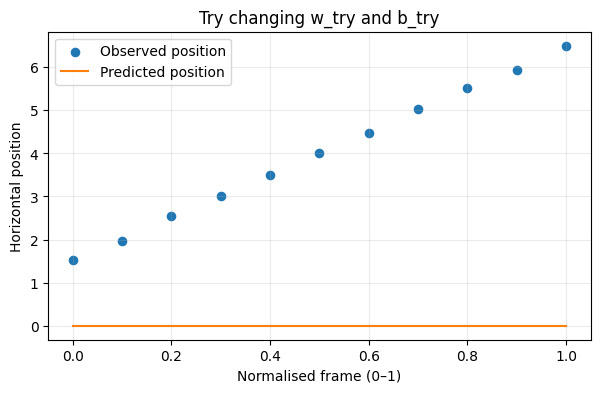

In [42]:
def plot_motion_fit(x, y, y_pred, title="Motion regression"):
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.scatter(x, y, label="Observed position", color="tab:blue", s=35)
    ax.plot(x, y_pred, label="Predicted position", color="tab:orange")
    ax.set(xlabel="Normalised frame (0–1)", ylabel="Horizontal position", title=title)
    ax.legend()
    ax.grid(alpha=0.25)
    plt.show()

# Try your own weight and bias. Change these TWO values and re-run.
w_try = 0.0
b_try = 0.0

y_try = predict(x, w_try, b_try)
print("MSE:", compute_mse(y, y_try))
plot_motion_fit(x, y, y_try, "Try changing w_try and b_try")

**Think:** If the line is consistently below all the points, which parameter is useful for moving it upwards? Which parameter controls its tilt?

## 04 · Gradient descent — 35 min

### 4.1 What is a derivative?

A derivative is the **local rate of change**: how much a function changes when its input changes slightly.

For a single data point, our prediction and squared error are:

$$
\hat y=wx+b,\qquad e=\hat y-y,\qquad L=e^2
$$

Using the **chain rule**, the effect of changing `w` passes through `ŷ` and then through `L`:

$$
\frac{\partial L}{\partial w}=2ex, \qquad
\frac{\partial L}{\partial b}=2e.
$$

For the mean over all `N` samples, the gradients are:

$$
\frac{\partial\mathrm{MSE}}{\partial w}=\frac{2}{N}\sum_{i=1}^{N}(\hat y_i-y_i)x_i,
\quad
\frac{\partial\mathrm{MSE}}{\partial b}=\frac{2}{N}\sum_{i=1}^{N}(\hat y_i-y_i).
$$

**Interpretation:** Each partial derivative tells us how the loss changes when we change **one parameter** while treating the other as fixed.

**Task 7:** Translate the **two mean-gradient formulas** above into NumPy. Your output must be two scalar values `(dw, db)`.

In [46]:
def compute_gradients(x, y_true, w, b):
    y_pred = predict(x, w, b)
    error = y_pred - y_true
    N = len(x)

    # TODO 1: Calculate the gradient with respect to weight w.
    dw = np.mean(error*x)*2

    # TODO 2: Calculate the gradient with respect to bias b.
    db = np.mean(error)*2

    return dw, db

# Simple independent check: x=[0,1], y=[1,3], w=b=0.
dw_test, db_test = compute_gradients(
    np.array([0.0, 1.0]), np.array([1.0, 3.0]), 0.0, 0.0
)
assert dw_test is not None and db_test is not None, "Fill in both gradients"
assert np.isclose(dw_test, -3.0)
assert np.isclose(db_test, -4.0)
print("Task 7 passed")

Task 7 passed


### 4.2 Why subtract the gradient?

Gradient descent updates the parameters **against** the direction of increasing loss:

$$
 w_{\mathrm{new}} = w - \alpha\,\frac{\partial L}{\partial w},\qquad
 b_{\mathrm{new}} = b - \alpha\,\frac{\partial L}{\partial b}.
$$

`α` is the **learning rate**. A very small learning rate can make training slow; a very large one can cause oscillation or divergence.

**Task 8:** Complete `gradient_step`: update *both* parameters, then return the new `(w, b)`.

In [67]:
def gradient_step(w, b, dw, db, learning_rate):
    w=w-learning_rate*dw
    b=b-learning_rate*db
    # TODO: Update w and b using gradient descent.
    return w,b

w_new, b_new = gradient_step(0.0, 0.0, -3.0, -4.0, 0.1)
assert np.isclose(w_new, 0.3)
assert np.isclose(b_new, 0.4)
print("Task 8 passed")

Task 8 passed


### 4.3 The training loop

An **epoch** is one complete pass through the training data. In each epoch:

1. Predict the positions.
2. Measure MSE.
3. Calculate gradients.
4. Update the parameters.

**Task 9:** Fill in the training loop. Reuse your functions; do not duplicate their calculations.

In [50]:
def train(x, y, learning_rate=0.1, epochs=400):
    w = 0.0
    b = 0.0
    losses = []

    for epoch in range(epochs):
        y_pred = predict(x, w, b)
        loss = compute_mse(y, y_pred)
        losses.append(loss)

        # TODO: Compute dw and db by calling the function you already wrote.
        dw, db=compute_gradients(x, y, w, b)
        # TODO: Update w and b by calling gradient_step().
        w,b=gradient_step(w, b, dw, db, learning_rate)
        
    return w, b, losses

Learned weight: 4.9653
Learned bias: 1.5194
First loss: 18.48642
Last recorded loss: 0.00088


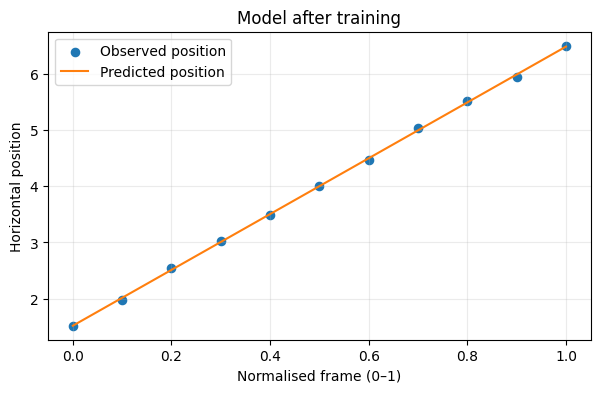

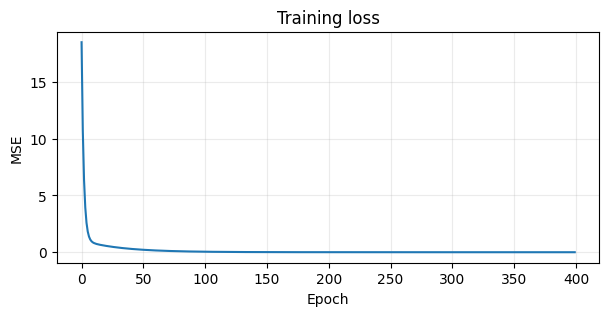

In [51]:
# Train your model once Task 9 is complete.
w_fit, b_fit, loss_history = train(x, y, learning_rate=0.1, epochs=400)

assert len(loss_history) == 400
assert np.isfinite(loss_history).all(), "Loss contains NaN or infinity"
assert loss_history[-1] < loss_history[0] * 0.05, "Training should reduce MSE substantially"

print("Learned weight:", round(w_fit, 4))
print("Learned bias:", round(b_fit, 4))
print("First loss:", round(loss_history[0], 5))
print("Last recorded loss:", round(loss_history[-1], 5))
plot_motion_fit(x, y, predict(x, w_fit, b_fit), "Model after training")

fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(loss_history)
ax.set(xlabel="Epoch", ylabel="MSE", title="Training loss")
ax.grid(alpha=0.25)
plt.show()

**Quick experiment (no new function):** Re-run the previous cell with a different `learning_rate`. What happens when it is much smaller? What happens if it is too large? If your loss becomes `NaN`, reset to `0.1`.

**Important:** A falling training loss does not, by itself, demonstrate good predictions on unseen data. Here, the aim is to understand and implement optimisation.

Learned weight: 1.324
Learned bias: 1.9735
First loss: 18.48642
Last recorded loss: 3.20972


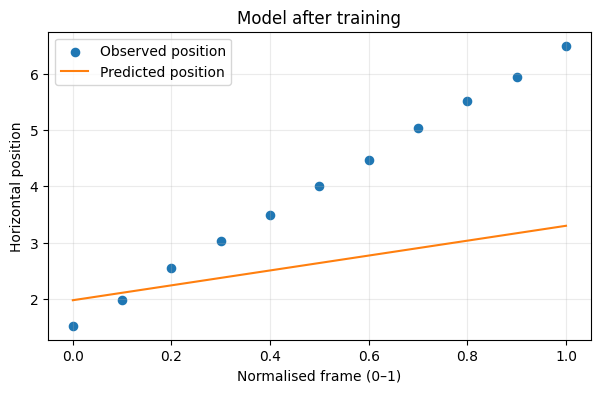

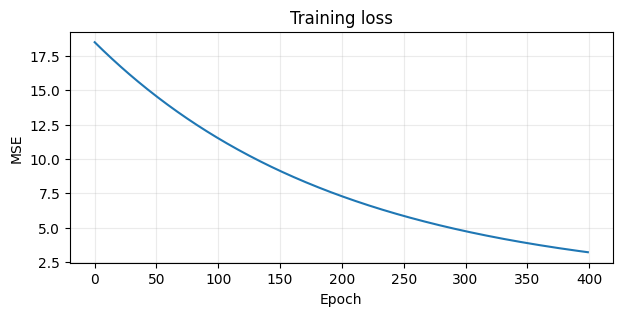

In [62]:
# Train your model once Task 9 is complete.
w_fit, b_fit, loss_history = train(x, y, learning_rate=0.001, epochs=400)

assert len(loss_history) == 400
#assert np.isfinite(loss_history).all(), "Loss contains NaN or infinity"
#assert loss_history[-1] < loss_history[0] * 0.05, "Training should reduce MSE substantially"

print("Learned weight:", round(w_fit, 4))
print("Learned bias:", round(b_fit, 4))
print("First loss:", round(loss_history[0], 5))
print("Last recorded loss:", round(loss_history[-1], 5))
plot_motion_fit(x, y, predict(x, w_fit, b_fit), "Model after training")

fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(loss_history)
ax.set(xlabel="Epoch", ylabel="MSE", title="Training loss")
ax.grid(alpha=0.25)
plt.show()
#能观察到lr过大无法收敛，过小则需要更多epochs

## 05 · From one input to multiple inputs — 10 min

Our one-variable model uses `x` with shape `(N,)` and a **single scalar weight**. Real models may have multiple input features for each sample.

For example, we could provide **time** and **time squared** as two features. This is still *linear regression in the weights*, even though it can describe a curved path in time:

$$
\hat{\mathbf y} = X\mathbf w+b,
\quad X\in\mathbb R^{N\times 2},\quad \mathbf w\in\mathbb R^{2}.
$$

`X @ w` computes one prediction per row. The scalar `b` is then added to every prediction by broadcasting.

**Task 10:** Complete the function with matrix multiplication. You do *not* need to train the multiple-input model in class.

In [84]:
X_two = np.column_stack([x, x**2])
w_two_demo = np.array([2.0, 3.0])

print("X_two.shape:", X_two.shape)
print("w_two_demo.shape:", w_two_demo.shape)

X_two.shape: (11, 2)
w_two_demo.shape: (2,)


In [85]:
def predict_multi(X, w, b):
    # TODO: Return one prediction per sample using @ and the bias.
    y_pred = X@w+b
    return y_pred

assert predict_multi(X_two, w_two_demo, 1.0).shape == (len(x),)
assert np.allclose(predict_multi(np.array([[1., 2.], [3., 4.]]),
                                 np.array([2., 1.]), 0.5), [4.5, 10.5])
print("Task 10 passed")

Task 10 passed


## 06 · Assignment — one extension, not five separate tasks

### Can linear regression model accelerating animation?

You have learned to fit approximately constant-speed movement. Now test **accelerating** horizontal movement. Finish the notebook in your own time and extend your model to use both `t` and `t²` as features.

**Required submission:** This completed `.ipynb` with all core task checks passing, plus **one short written conclusion** beneath the last plot (about 100–150 words). In your conclusion, state how the one-feature and two-feature models differ and what happens when you change the learning rate.

The code below creates a second, curved motion trajectory. In this assignment you need to:

1. Use your completed `train()` to fit a **one-feature** model to the new data.
2. Implement **one new function**, `train_multi()`, using `predict_multi()` and the matrix-gradient formula below.
3. Plot both sets of predictions alongside the ground truth and interpret the results.

For multiple regression with MSE:

$$
\nabla_{\mathbf w} L=\frac{2}{N}X^T(X\mathbf w+b-\mathbf y),
\qquad
\frac{\partial L}{\partial b}=\frac{2}{N}\sum_i(\hat y_i-y_i).
$$

You may reuse the previous plotting helper and other utility code. **Do not use `sklearn` to train this model.**

One-feature shape: (11,)
Two-feature shape: (11, 2)


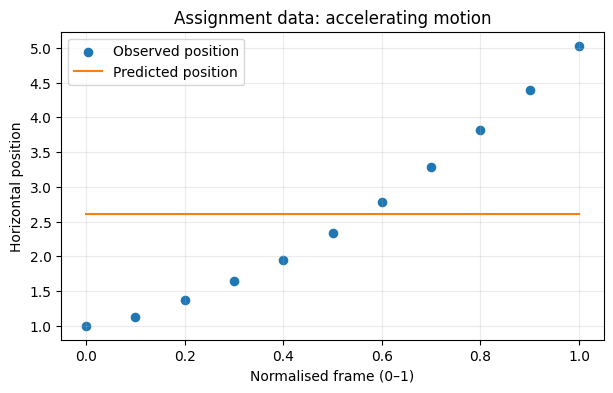

In [65]:
# Assignment data: curved (accelerating) motion.
# The target is deliberately NOT a straight line.
t_assignment = x.copy()
y_accelerating = np.array([
    1.00, 1.13, 1.37, 1.65, 1.95, 2.34,
    2.78, 3.28, 3.82, 4.39, 5.03
], dtype=float)
X_assignment = np.column_stack([t_assignment, t_assignment**2])

print("One-feature shape:", t_assignment.shape)
print("Two-feature shape:", X_assignment.shape)
plot_motion_fit(t_assignment, y_accelerating,
                np.full_like(y_accelerating, np.mean(y_accelerating)),
                "Assignment data: accelerating motion")

In [ ]:
# Assignment Part A — Reuse your completed one-variable training function.
# TODO: Train on (t_assignment, y_accelerating).
# Hint: save the result as w_linear, b_linear, linear_losses.

# w_linear, b_linear, linear_losses = ...

In [95]:
X_assignment.shape

(11, 2)

In [98]:
X_assignment.T.shape

(2, 11)

In [82]:
y_accelerating.shape

(11,)

In [157]:
def train_multi(X, y, learning_rate=0.1, epochs=1500):
    # TODO: Initialise a weight VECTOR of zeros (one value per feature),
    #       and aw=np.array([0, 0]) scalar bias of zero.
    w =np.array([0, 0])
    b=0
    losses=[]
    # TODO: In each epoch, predict, compute and store MSE,
    #       calculate vector/scalar gradients using the formula above,
    #       and update weights and bias.
    for epoch in range(epochs):
        y_pred = predict_multi(X, w, b)
        loss = compute_mse(y, y_pred)
        losses.append(loss)
        error = (y_pred-y)
        
        # TODO 1: Calculate the gradient with respect to weight w.
        dw = (2/len(X))*(X.T)@error
        # TODO 2: Calculate the gradient with respect to bias b.
        db = np.mean(error)*2

        w=w-learning_rate*dw
        b=b-learning_rate*db
        
    # TODO: Return (weights, bias, loss_history).
    return w, b, losses

In [158]:
w_multi, b_multi, multi_losses = train_multi(X_assignment, y_accelerating)
print("Trained weights:", w_multi, "bias:", b_multi)

Trained weights: [1.61468541 2.45149652] bias: 0.9472250568503956


In [ ]:
# Assignment Part C — Compare both models visually.
# TODO: Use your trained parameters from Part A and B.
# TODO: Plot observed positions, the one-feature prediction,
#       and the two-feature prediction on the SAME axes.
# TODO: Plot or compare the MSE histories and write a short conclusion.

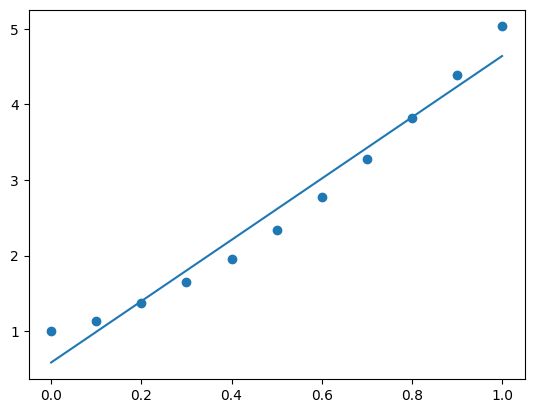

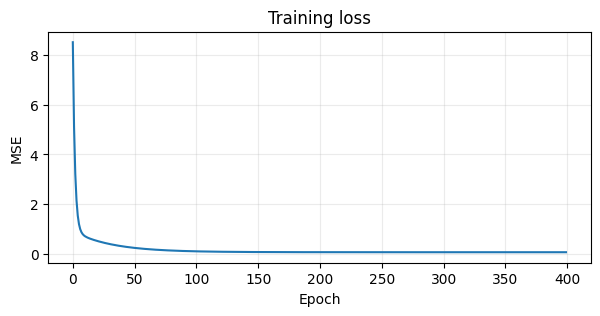

In [163]:
w_fit, b_fit, loss_history = train(t_assignment, y_accelerating, learning_rate=0.1, epochs=400)
y_pred_linear = predict(t_assignment, w_fit, b_fit)
plt.scatter(t_assignment, y_accelerating, label="Observed")
plt.plot(t_assignment, y_pred_linear, label="One feature")

fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(loss_history)
ax.set(xlabel="Epoch", ylabel="MSE", title="Training loss")
ax.grid(alpha=0.25)
plt.show()

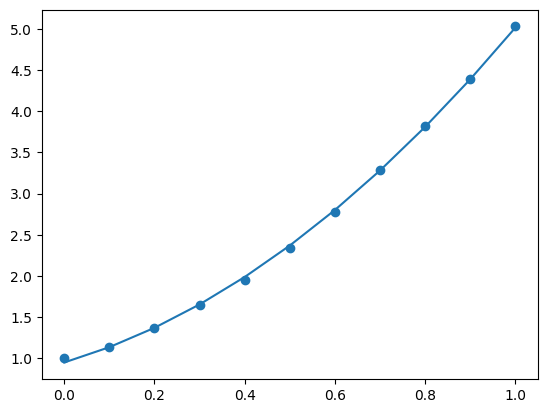

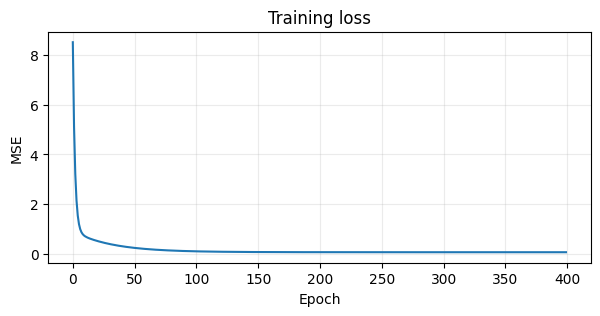

In [168]:
y_pred_multi = predict_multi(X_assignment, w_multi, b_multi)

plt.scatter(t_assignment, y_accelerating, label="Observed")
plt.plot(t_assignment, y_pred_multi, label="One feature")

fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(loss_history)
ax.set(xlabel="Epoch", ylabel="MSE", title="Training loss")
ax.grid(alpha=0.25)
plt.show()

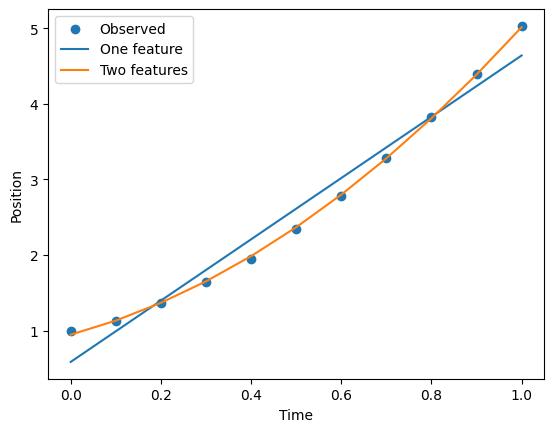

In [167]:
plt.scatter(t_assignment, y_accelerating, label="Observed")
plt.plot(t_assignment, y_pred_linear, label="One feature")
plt.plot(t_assignment, y_pred_multi, label="Two features")

plt.xlabel("Time")
plt.ylabel("Position")
plt.legend()
plt.show()

### Assignment conclusion (100–150 words)

**Your explanation:**

> TODO: What happened when you fitted accelerating motion with one feature versus two? Why? What effect did the learning rate have? What are the limitations of checking only training loss?

---

### Self-check before submitting

- [ ] I can explain `return` vs `print` and `for value in values`.
- [ ] I can distinguish an array of shape `(N,)` from `(N, 1)`.
- [ ] I can explain `*` vs `@`.
- [ ] I can explain what weight, bias, residual and MSE mean.
- [ ] I can point to the code implementing the two derivatives.
- [ ] My training loss goes down and I know why.
- [ ] I can explain why adding `t²` allows a curved prediction even though the model is linear in its weights.

**One model, one notebook, one assignment.**